In [2]:
# ===== Cell 1: Environment Setup =====

!pip -q install vmas

import vmas
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import json

from pathlib import Path
from google.colab import drive

# 1. 连接 Google Drive
drive.mount("/content/drive")

# 2. 创建项目路径
ROOT = Path("/content/drive/MyDrive/MAWM_Research")
E4_DIR = ROOT / "E4"
PD_DIR = E4_DIR / "PD_baselines"
CEM_DIR = E4_DIR / "CEM_baselines"

CEM_DIR.mkdir(parents=True, exist_ok=True)

# 3. 选择计算设备
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 4. 实验基本参数
MAX_STEPS = 200
SAFE_DISTANCE = 0.30
GOAL_TOL = 0.12
SEED = 42

# 5. 两个 Agent 的固定起点
STARTS = np.array([
    [-0.8, -0.8],  # Agent 0
    [-0.8,  0.8]   # Agent 1
], dtype=np.float32)

# 6. 两个 Agent 的目标位置
GOALS = np.array([
    [0.8,  0.8],   # Agent 0
    [0.8, -0.8]    # Agent 1
], dtype=np.float32)

# 7. 固定随机种子
np.random.seed(SEED)
torch.manual_seed(SEED)

print("===== E4-A Initialization =====")
print("Device:", DEVICE)
print("VMAS installed successfully")
print("Result directory:", CEM_DIR)
print("Starting positions:\n", STARTS)
print("Goal positions:\n", GOALS)# ===== Cell 1: Environment Setup =====

!pip -q install vmas

import vmas
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import json

from pathlib import Path
from google.colab import drive

# 1. 连接 Google Drive
drive.mount("/content/drive")

# 2. 创建项目路径
ROOT = Path("/content/drive/MyDrive/MAWM_Research")
E4_DIR = ROOT / "E4"
PD_DIR = E4_DIR / "PD_baselines"
CEM_DIR = E4_DIR / "CEM_baselines"

CEM_DIR.mkdir(parents=True, exist_ok=True)

# 3. 选择计算设备
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 4. 实验基本参数
MAX_STEPS = 200
SAFE_DISTANCE = 0.30
GOAL_TOL = 0.12
SEED = 42

# 5. 两个 Agent 的固定起点
STARTS = np.array([
    [-0.8, -0.8],  # Agent 0
    [-0.8,  0.8]   # Agent 1
], dtype=np.float32)

# 6. 两个 Agent 的目标位置
GOALS = np.array([
    [0.8,  0.8],   # Agent 0
    [0.8, -0.8]    # Agent 1
], dtype=np.float32)

# 7. 固定随机种子
np.random.seed(SEED)
torch.manual_seed(SEED)

print("===== E4-A Initialization =====")
print("Device:", DEVICE)
print("VMAS installed successfully")
print("Result directory:", CEM_DIR)
print("Starting positions:\n", STARTS)
print("Goal positions:\n", GOALS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
===== E4-A Initialization =====
Device: cpu
VMAS installed successfully
Result directory: /content/drive/MyDrive/MAWM_Research/E4/CEM_baselines
Starting positions:
 [[-0.8 -0.8]
 [-0.8  0.8]]
Goal positions:
 [[ 0.8  0.8]
 [ 0.8 -0.8]]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
===== E4-A Initialization =====
Device: cpu
VMAS installed successfully
Result directory: /content/drive/MyDrive/MAWM_Research/E4/CEM_baselines
Starting positions:
 [[-0.8 -0.8]
 [-0.8  0.8]]
Goal positions:
 [[ 0.8  0.8]
 [ 0.8 -0.8]]


In [3]:
# ===== Cell 2: Fixed Navigation Scenario =====

def create_scenario():

    # 1. 创建双 Agent Navigation 环境
    environment = vmas.make_env(
        scenario="navigation",
        num_envs=1,
        n_agents=2,
        device=DEVICE,
        continuous_actions=True,
        max_steps=MAX_STEPS,
        seed=SEED
    )

    # 2. 重置环境
    environment.reset()

    # 3. 设置固定起点与目标
    with torch.no_grad():

        for i, agent in enumerate(environment.agents):

            pos = torch.tensor(
                STARTS[i],
                dtype=torch.float32,
                device=DEVICE
            )

            goal = torch.tensor(
                GOALS[i],
                dtype=torch.float32,
                device=DEVICE
            )

            # 设置 Agent 初始位置
            agent.set_pos(pos, batch_index=0)

            # 设置 Agent 初始速度为 0
            agent.set_vel(
                torch.zeros(2, device=DEVICE),
                batch_index=0
            )

            # 设置对应的 Goal 位置
            agent.goal.set_pos(goal, batch_index=0)

            # 更新 Navigation 奖励整形基准
            if hasattr(agent, "pos_shaping"):
                agent.pos_shaping[0] = (
                    torch.linalg.vector_norm(pos - goal)
                    * environment.scenario.pos_shaping_factor
                )

    return environment


# ===== Test Scenario =====

test_env = create_scenario()

print("===== Scenario Verification =====")
print("Number of agents:", len(test_env.agents))

for i, agent in enumerate(test_env.agents):

    print(f"\nAgent {i}")
    print("Start:",
          agent.state.pos[0].detach().cpu().numpy())
    print("Goal:",
          agent.goal.state.pos[0].detach().cpu().numpy())
    print("Velocity:",
          agent.state.vel[0].detach().cpu().numpy())

print("\nFixed crossing scenario created successfully!")

===== Scenario Verification =====
Number of agents: 2

Agent 0
Start: [-0.8 -0.8]
Goal: [0.8 0.8]
Velocity: [0. 0.]

Agent 1
Start: [-0.8  0.8]
Goal: [ 0.8 -0.8]
Velocity: [0. 0.]

Fixed crossing scenario created successfully!


In [21]:
#Step 16：配置 CEM 参数
#先用少量候选动作做 Smoke Test，以免一开始消耗过多 Colab 计算资源。
CEM_CONFIG = {
    "horizon": 8,
    "population": 64,
    "iterations": 3,
    "elite_fraction": 0.125,
    "max_steps": 30,
    "goal_weight": 5.0,
    "action_weight": 0.01,
    "seed": 42
}

CEM_DIR = ROOT / "E4" / "CEM_baselines"
CEM_DIR.mkdir(parents=True, exist_ok=True)

print(CEM_CONFIG)

{'horizon': 8, 'population': 64, 'iterations': 3, 'elite_fraction': 0.125, 'max_steps': 30, 'goal_weight': 5.0, 'action_weight': 0.01, 'seed': 42}


In [11]:
#Step 17：建立批量真实仿真器
#VMAS 支持 num_envs 向量化仿真，而且支持通过 set_pos() 和 set_vel() 设置指定物理状态。我们将利用这些能力，同时评估多条候选动作。
# ===== Fixed Step 17: Batch State Initialization =====

def create_cem_simulator(batch_size):
    """Create the vectorized VMAS Navigation simulator used by CEM."""
    return vmas.make_env(
        scenario="navigation",
        num_envs=batch_size,
        n_agents=2,
        device=DEVICE,
        continuous_actions=True,
        max_steps=MAX_STEPS,
        seed=SEED
    )


def set_cem_state(sim, positions, velocities):
    """
    positions: [2, 2]
    velocities: [2, 2]

    将全部候选仿真环境初始化到相同状态。
    """

    batch = sim.num_envs
    device = sim.device

    sim.reset()

    with torch.no_grad():

        for i, agent in enumerate(sim.agents):

            p = torch.as_tensor(
                positions[i],
                device=device,
                dtype=torch.float32
            ).reshape(1, 2).expand(batch, -1).clone()

            v = torch.as_tensor(
                velocities[i],
                device=device,
                dtype=torch.float32
            ).reshape(1, 2).expand(batch, -1).clone()

            g = torch.as_tensor(
                GOALS[i],
                device=device,
                dtype=torch.float32
            ).reshape(1, 2).expand(batch, -1).clone()

            # 关键修复：指定 batch_index=None
            agent.set_pos(p, batch_index=None)
            agent.set_vel(v, batch_index=None)
            agent.goal.set_pos(g, batch_index=None)

            if hasattr(agent, "pos_shaping"):
                agent.pos_shaping[:] = (
                    torch.linalg.vector_norm(p - g, dim=-1)
                    * sim.scenario.pos_shaping_factor
                )

    return sim

In [12]:
#Step 18：实现 Independent CEM 规划器
import math

def independent_cem(
    sim,
    positions,
    velocities,
    agent_id,
    config,
    seed=42
):
    device = sim.device
    B = config["population"]
    H = config["horizon"]

    # 确认批量仿真器尺寸正确
    assert sim.num_envs == B

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    action_limit = float(sim.agents[agent_id].u_range)

    mean = torch.zeros(H, 2, device=device)
    std = torch.ones(H, 2, device=device) * 0.6

    elite_count = max(
        2, int(B * config["elite_fraction"])
    )

    best_action = None
    best_cost = float("inf")

    target = torch.as_tensor(
        GOALS[agent_id],
        device=device,
        dtype=torch.float32
    )

    for iteration in range(config["iterations"]):

        noise = torch.randn(
            B, H, 2,
            generator=generator,
            device=device
        )

        candidates = torch.clamp(
            mean.unsqueeze(0) + std.unsqueeze(0) * noise,
            -action_limit,
            action_limit
        )

        # 从相同真实状态开始所有候选仿真
        set_cem_state(sim, positions, velocities)

        # Independent 假设：
        # 伙伴当前静止，候选期内输入零动作
        with torch.no_grad():
            sim.agents[1-agent_id].set_vel(
              torch.zeros(
                B, 2,
                device=device,
                dtype=torch.float32
              ),
              batch_index=None
            )

            for h in range(H):
                actions = [
                    torch.zeros(
                        B, 2,
                        device=device,
                        dtype=torch.float32
                    )
                    for _ in range(2)
                ]

                actions[agent_id] = candidates[:, h, :]

                sim.step(actions)

            final_pos = sim.agents[agent_id].state.pos

            goal_cost = torch.linalg.vector_norm(
                final_pos - target, dim=-1
            )

            action_cost = torch.mean(
                candidates.pow(2), dim=(1, 2)
            )

            costs = (
                config["goal_weight"] * goal_cost
                + config["action_weight"] * action_cost
            )

        # 选择 Elite 动作序列
        elite_indices = torch.topk(
            costs, k=elite_count, largest=False
        ).indices

        elite_actions = candidates[elite_indices]

        mean = elite_actions.mean(dim=0)
        std = elite_actions.std(dim=0, unbiased=False)
        std = torch.clamp(std, min=0.05)

        winner = torch.argmin(costs)
        current_cost = float(costs[winner].item())

        if current_cost < best_cost:
            best_cost = current_cost
            best_action = candidates[winner, 0].clone()

    return best_action, best_cost

In [ ]:
# ===== Batch Simulator and State Setup =====

# Create every object required by the following verification and planning cells.
# Keeping this setup in the notebook makes a fresh-kernel Run All deterministic.
cem_env = create_scenario()

positions = np.stack([
    agent.state.pos[0].detach().cpu().numpy()
    for agent in cem_env.agents
])

velocities = np.stack([
    agent.state.vel[0].detach().cpu().numpy()
    for agent in cem_env.agents
])

cem_sim = create_cem_simulator(
    CEM_CONFIG["population"]
)


In [13]:
# ===== Batch State Verification =====

set_cem_state(cem_sim, positions, velocities)

print("Number of parallel environments:", cem_sim.num_envs)

for i, agent in enumerate(cem_sim.agents):
    print(f"\nAgent {i}")
    print("Position shape:", agent.state.pos.shape)
    print("Velocity shape:", agent.state.vel.shape)
    print("Goal shape:", agent.goal.state.pos.shape)

    print("First environment position:",
          agent.state.pos[0].detach().cpu().numpy())

    print("Last environment position:",
          agent.state.pos[-1].detach().cpu().numpy())

Number of parallel environments: 64

Agent 0
Position shape: torch.Size([64, 2])
Velocity shape: torch.Size([64, 2])
Goal shape: torch.Size([64, 2])
First environment position: [-0.8 -0.8]
Last environment position: [-0.8 -0.8]

Agent 1
Position shape: torch.Size([64, 2])
Velocity shape: torch.Size([64, 2])
Goal shape: torch.Size([64, 2])
First environment position: [-0.8  0.8]
Last environment position: [-0.8  0.8]


In [14]:
#Step 19：先执行一次 CEM 规划测试
# 建立当前真实环境
cem_env = create_scenario()

# 提取初始状态
positions = np.stack([
    a.state.pos[0].detach().cpu().numpy()
    for a in cem_env.agents
])

velocities = np.stack([
    a.state.vel[0].detach().cpu().numpy()
    for a in cem_env.agents
])

# 建立64个并行候选环境
cem_sim = create_cem_simulator(
    CEM_CONFIG["population"]
)

# 单独规划 Agent 0
action0, cost0 = independent_cem(
    cem_sim, positions, velocities,
    agent_id=0,
    config=CEM_CONFIG,
    seed=42
)

# 单独规划 Agent 1
action1, cost1 = independent_cem(
    cem_sim, positions, velocities,
    agent_id=1,
    config=CEM_CONFIG,
    seed=43
)

print("Agent 0 action:", action0)
print("Agent 0 cost:", cost0)
print("Agent 1 action:", action1)
print("Agent 1 cost:", cost1)

Agent 0 action: tensor([1.0000, 0.6581])
Agent 0 cost: 10.54218578338623
Agent 1 action: tensor([ 0.7502, -0.9562])
Agent 1 cost: 10.566337585449219


In [15]:
#Step 20：运行 30 步 Independent CEM
def run_independent_cem_test(config):
    real_env = create_scenario()
    sim = create_cem_simulator(config["population"])

    trajectories = [[], []]
    separations = []
    planning_times = []
    predicted_costs = [[], []]

    termination = "smoke_test_limit"

    def record():
        ps = [
            a.state.pos[0].detach().cpu().numpy().copy()
            for a in real_env.agents
        ]
        for i in range(2):
            trajectories[i].append(ps[i])

        separations.append(
            float(np.linalg.norm(ps[0] - ps[1]))
        )

    record()

    for step in range(config["max_steps"]):
        positions = np.stack([
            a.state.pos[0].detach().cpu().numpy()
            for a in real_env.agents
        ])

        velocities = np.stack([
            a.state.vel[0].detach().cpu().numpy()
            for a in real_env.agents
        ])

        goal_dist = np.linalg.norm(
            positions - GOALS, axis=1
        )

        if np.all(goal_dist < GOAL_TOL):
            termination = "joint_success"
            break

        t0 = time.perf_counter()
        actions = []

        for i in range(2):
            action, cost = independent_cem(
                sim, positions, velocities,
                agent_id=i,
                config=config,
                seed=config["seed"] + step * 2 + i
            )

            actions.append(action.unsqueeze(0))
            predicted_costs[i].append(cost)

        # GPU 操作异步，统计前需要同步
        if str(sim.device).startswith("cuda"):
            torch.cuda.synchronize()

        planning_times.append(
            (time.perf_counter() - t0) * 1000
        )

        _, _, dones, _ = real_env.step(actions)
        record()

        if bool(torch.all(dones)):
            termination = "environment_done"
            break

    final_positions = np.stack([
        a.state.pos[0].detach().cpu().numpy()
        for a in real_env.agents
    ])

    success = bool(np.all(
        np.linalg.norm(final_positions-GOALS, axis=1)
        < GOAL_TOL
    ))

    if success:
        termination = "joint_success"

    trajectories = [np.asarray(t) for t in trajectories]
    separations = np.asarray(separations)

    collision_threshold = sum(
        float(a.shape.radius) for a in real_env.agents
    )

    result = {
        "experiment": "E4-A",
        "method": "Independent_CEM_TrueDynamics",
        "steps": len(separations)-1,
        "joint_success": success,
        "termination": termination,
        "minimum_separation": float(separations.min()),
        "loss_of_separation": bool(
            np.any(separations < SAFE_DISTANCE)
        ),
        "collision_proxy": bool(
            np.any(separations < collision_threshold)
        ),
        "mean_planning_ms": float(np.mean(planning_times))
            if planning_times else 0.0,
        "planning_times_ms": planning_times,
        "final_goal_distances": np.linalg.norm(
            final_positions-GOALS, axis=1
        ).tolist()
    }

    return result, trajectories, separations


cem_result, cem_trajectories, cem_separations = (
    run_independent_cem_test(CEM_CONFIG)
)

print(json.dumps(cem_result, indent=2))

{
  "experiment": "E4-A",
  "method": "Independent_CEM_TrueDynamics",
  "steps": 30,
  "joint_success": false,
  "termination": "smoke_test_limit",
  "minimum_separation": 0.23025889694690704,
  "loss_of_separation": true,
  "collision_proxy": false,
  "mean_planning_ms": 135.4059125000049,
  "planning_times_ms": [
    110.73231099999248,
    106.61968200020056,
    101.88029200003257,
    117.86474099994848,
    105.60265100002653,
    102.77250200010712,
    103.08444199995392,
    108.38037200005601,
    104.38089199988099,
    108.64532200002941,
    105.89050099997621,
    102.34338200007187,
    118.3605510000234,
    106.02144199992836,
    134.5824499999253,
    171.0944860001291,
    153.19847799992203,
    146.57985899998494,
    139.8407290000705,
    147.45847899985165,
    187.99399599993194,
    156.68101799997203,
    151.22079900015706,
    146.23509900002318,
    172.43383599998197,
    150.27124800008096,
    181.74993600018752,
    153.1881579999208,
    197.21250399

In [18]:
#加载之前保存的 PD 轨迹
# ===== Load Previous PD Baseline =====

import numpy as np

PD_DIR = ROOT / "E4" / "PD_baselines"

pd_file = PD_DIR / "S1_trajectories.npz"

pd_data = np.load(pd_file)

# 恢复 Independent PD 轨迹
traj_a = [
    pd_data["independent_agent0"],
    pd_data["independent_agent1"]
]

# 恢复 Priority PD 轨迹（后续可能用到）
traj_b = [
    pd_data["priority_agent0"],
    pd_data["priority_agent1"]
]

sep_a = pd_data["independent_separation"]
sep_b = pd_data["priority_separation"]

print("PD data loaded successfully!")
print("Independent PD:", [t.shape for t in traj_a])
print("Priority PD:", [t.shape for t in traj_b])

PD data loaded successfully!
Independent PD: [(201, 2), (201, 2)]
Priority PD: [(151, 2), (151, 2)]


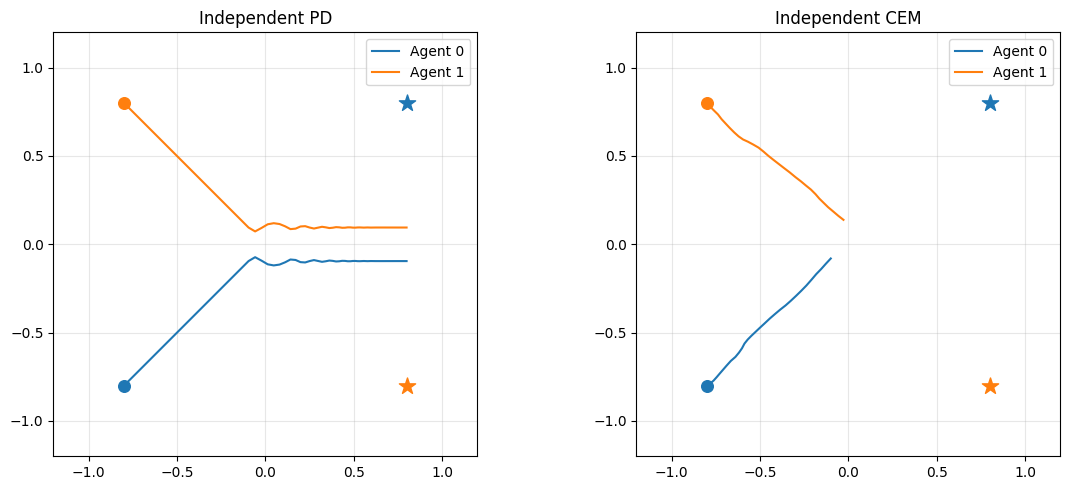

E4-A smoke test saved to Google Drive.


In [19]:
#Step 21：绘制并保存 CEM 轨迹
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, trajectories, title in [
    (axes[0], traj_a, "Independent PD"),
    (axes[1], cem_trajectories, "Independent CEM")
]:
    for i, trajectory in enumerate(trajectories):
        color = ["tab:blue", "tab:orange"][i]
        ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            color=color,
            label=f"Agent {i}"
        )
        ax.scatter(*STARTS[i], color=color, s=70)
        ax.scatter(*GOALS[i], color=color, marker="*", s=150)

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(title)
    ax.legend()

fig.tight_layout()
fig.savefig(
    CEM_DIR / "E4A_CEM_smoke_trajectories.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

with open(CEM_DIR / "E4A_CEM_smoke_results.json", "w") as f:
    json.dump(cem_result, f, indent=2)

np.savez_compressed(
    CEM_DIR / "E4A_CEM_smoke_trajectories.npz",
    agent0=cem_trajectories[0],
    agent1=cem_trajectories[1],
    separation=cem_separations
)

with open(CEM_DIR / "E4A_CEM_smoke_config.json", "w") as f:
    json.dump(CEM_CONFIG, f, indent=2)

print("E4-A smoke test saved to Google Drive.")

In [20]:
#确认保存成功
print("===== Saved CEM Files =====")

for file in sorted(CEM_DIR.iterdir()):
    print(file.name)

===== Saved CEM Files =====
E4A_CEM_smoke_config.json
E4A_CEM_smoke_results.json
E4A_CEM_smoke_trajectories.npz
E4A_CEM_smoke_trajectories.png


In [22]:
#Step 22：运行 200-step 完整实验

# ===== Step 22: Full E4-A Experiment =====

CEM_CONFIG["max_steps"] = 200

cem_result_full, cem_traj_full, cem_sep_full = (
    run_independent_cem_test(CEM_CONFIG)
)

print("===== E4-A Full Experiment =====")
print(json.dumps(cem_result_full, indent=2))

===== E4-A Full Experiment =====
{
  "experiment": "E4-A",
  "method": "Independent_CEM_TrueDynamics",
  "steps": 68,
  "joint_success": true,
  "termination": "joint_success",
  "minimum_separation": 0.17508655786514282,
  "loss_of_separation": true,
  "collision_proxy": true,
  "mean_planning_ms": 109.34383880880084,
  "planning_times_ms": [
    109.57542699998157,
    107.22795699985,
    116.76712600001338,
    103.53586900009759,
    102.6230279999254,
    102.62537800008431,
    103.03285800000594,
    102.1984489998431,
    105.06588799989913,
    111.61123700003373,
    103.31533899989154,
    119.19711599966831,
    104.67108800003189,
    101.75972800016098,
    102.03960800026834,
    103.8430779999544,
    101.47252900014792,
    104.00258800018491,
    108.60989799994059,
    103.80843899974934,
    105.29079800016916,
    116.43126699982531,
    108.10514800004967,
    104.16379799971764,
    102.63277800004289,
    103.32956799993553,
    102.06362799999624,
    107.7817

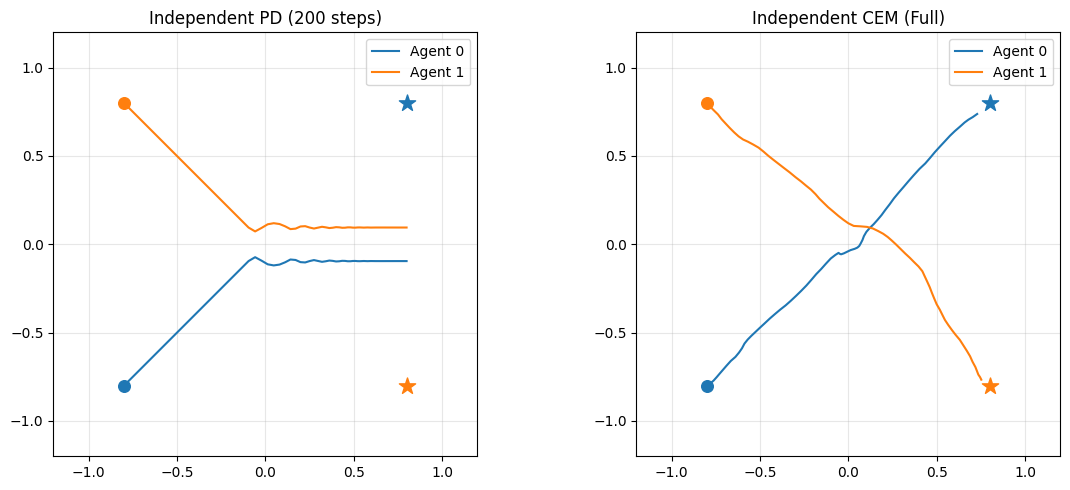

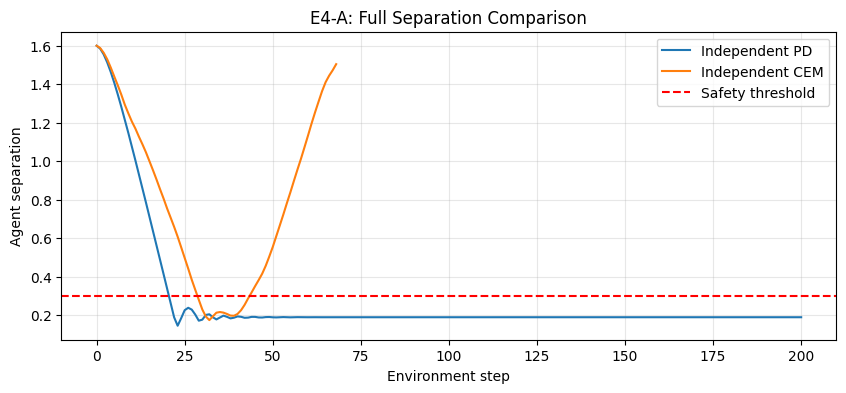

Full E4-A results saved successfully!


In [23]:
#Step 23：绘制并保存完整实验结果
# ===== Step 23: Visualize and Save Full Experiment =====

import matplotlib.pyplot as plt
import numpy as np
import json

# 1. 绘制 PD 与 200-step CEM 轨迹对照图
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ["tab:blue", "tab:orange"]

for ax, trajectories, title in [
    (axes[0], traj_a, "Independent PD (200 steps)"),
    (axes[1], cem_traj_full, "Independent CEM (Full)")
]:
    for i, trajectory in enumerate(trajectories):
        ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            color=colors[i],
            label=f"Agent {i}"
        )

        ax.scatter(
            *STARTS[i],
            color=colors[i],
            s=70
        )

        ax.scatter(
            *GOALS[i],
            color=colors[i],
            marker="*",
            s=150
        )

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()

fig.savefig(
    CEM_DIR / "E4A_full_trajectory_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 2. 绘制安全间隔对照曲线
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(sep_a, label="Independent PD")
ax.plot(cem_sep_full, label="Independent CEM")

ax.axhline(
    SAFE_DISTANCE,
    color="red",
    linestyle="--",
    label="Safety threshold"
)

ax.set_xlabel("Environment step")
ax.set_ylabel("Agent separation")
ax.set_title("E4-A: Full Separation Comparison")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(
    CEM_DIR / "E4A_full_separation_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 3. 保存 JSON
with open(CEM_DIR / "E4A_CEM_full_results.json", "w") as f:
    json.dump(cem_result_full, f, indent=2)

# 4. 保存轨迹数组
np.savez_compressed(
    CEM_DIR / "E4A_CEM_full_trajectories.npz",
    agent0=cem_traj_full[0],
    agent1=cem_traj_full[1],
    separation=cem_sep_full
)

# 5. 保存实验配置
with open(CEM_DIR / "E4A_CEM_full_config.json", "w") as f:
    json.dump(CEM_CONFIG, f, indent=2)

print("Full E4-A results saved successfully!")

In [24]:
#Step 24：确认所有文件保存成功

# ===== Step 24: Verify Saved Files =====

print("===== E4-A Saved Files =====")

for file in sorted(CEM_DIR.iterdir()):
    print(file.name)

===== E4-A Saved Files =====
E4A_CEM_full_config.json
E4A_CEM_full_results.json
E4A_CEM_full_trajectories.npz
E4A_CEM_smoke_config.json
E4A_CEM_smoke_results.json
E4A_CEM_smoke_trajectories.npz
E4A_CEM_smoke_trajectories.png
E4A_full_separation_comparison.png
E4A_full_trajectory_comparison.png
